Problem 2: Regresija

Feature: 1, w = [-0.89585316], bias = 0.0009031411027535796
Feature: 2, w = [-0.9651424 -0.3396172], bias = 0.3379845917224884
Feature: 3, w = [-1.0972358  -0.3108818   0.09232473], bias = 0.33099424839019775
Feature: 4, w = [-1.0514026   0.02597864  0.03657701 -0.1378481 ], bias = 0.2114516794681549
Feature: 5, w = [-0.9624442  -0.0415552  -0.16400488 -0.0882577   0.07982475], bias = 0.21590833365917206
Feature: 6, w = [-0.9714229  -0.08119246 -0.1722959  -0.09624018  0.09056185  0.01109522], bias = 0.2309848964214325


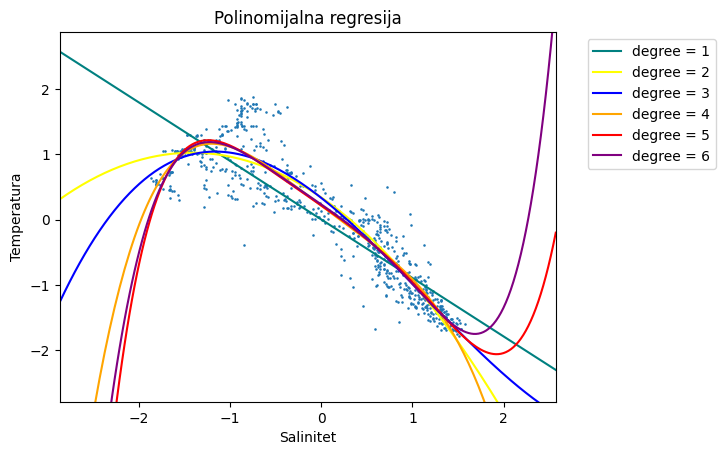

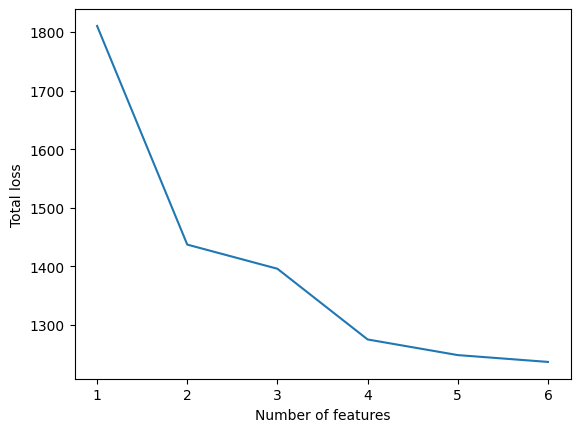

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


#od niza trening primera pravi matricu featura
def create_feature_matrix(x,nb_features):
  tmp_features = []
  for deg in range(1, nb_features+1):
    tmp_features.append(np.power(x, deg))
  return np.column_stack(tmp_features)


#ucitavanje podataka
filename = 'bottle.csv'
data = dict()

#preskakanje Nan vrednosti (zato se koristi genfromtxt)
all_data = np.genfromtxt(filename, delimiter=',', usecols=(5,6),dtype='float32',invalid_raise=False)
filtered_data = all_data[~np.isnan(all_data).any(axis=1)]

data['x'] = filtered_data[:700,1]
data['y'] = filtered_data[:700,0]

#shuffle
nb_samples = len(data['x'])
indices = np.random.permutation(nb_samples)
data['x'] = data['x'][indices]
data['y'] = data['y'][indices]

#normalizacija
data['x'] = (data['x'] - np.mean(data['x'], axis=0)) / np.std(data['x'], axis=0)
data['y'] = (data['y'] - np.mean(data['y'])) / np.std(data['y'])

#granice za grafik
min_x = np.min(data['x'])
max_x = np.max(data['x'])
min_y = np.min(data['y'])
max_y = np.max(data['y'])

#plotovanje
plt.figure()
plt.scatter(data['x'], data['y'], s=0.7)
plt.title("Polinomijalna regresija")
plt.xlabel('Salinitet')
plt.ylabel('Temperatura')
colours = ['teal', 'yellow', 'blue', 'orange', 'red', 'purple']

#--------------
def prediction(x, w, b, nb_features):
  w_col = tf.reshape(w, (nb_features,1))
  hyp = tf.add(tf.matmul(x, w_col), b)
  return hyp

def loss(x, y, w, b, nb_features):
  pred = prediction(x, w, b, nb_features)

  y_col = tf.reshape(y, (-1,1))
  loss = tf.reduce_mean(tf.square(pred-y_col))

  return loss

def calc_grad(x,y,w,b, nb_features):
  with tf.GradientTape() as tape:
    loss_val = loss(x, y, w, b, nb_features)

  w_grad, b_grad = tape.gradient(loss_val, [w, b])

  return w_grad, b_grad, loss_val


def train_step(x, y, w, b, nb_features, adam):

  w_grad, b_grad, loss = calc_grad(x, y, w, b, nb_features)

  adam.apply_gradients(zip([w_grad, b_grad], [w, b]))

  return loss

original_data = data['x']

def feature_run(nb_features):

  data['x'] = create_feature_matrix(original_data, nb_features)

  w = tf.Variable(tf.zeros(nb_features))
  b = tf.Variable(0.0)

  learning_rate = 0.001
  epochs = 10
  adam = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  total_loss = 0

  for e in range(epochs):

    for sample in range(nb_samples):
      x = data['x'][sample].reshape((1, nb_features))
      y = data['y'][sample]

      curr_loss = train_step(x, y, w, b, nb_features,adam)
      total_loss += curr_loss

  print(f'Feature: {nb_features}, w = {w.numpy()}, bias = {b.numpy()}')
  xs = create_feature_matrix(np.linspace(min_x-1, max_x+1, 200, dtype='float32'), nb_features)
  hyp_val = prediction(xs, w, b, nb_features)
  plt.plot(xs[:, 0].tolist(), hyp_val.numpy().tolist(), color=colours[nb_features-1], label=f'degree = {nb_features}')
  plt.xlim([min_x-1, max_x+1])
  plt.ylim([min_y-1, max_y+1])

  return total_loss

#pokrece se za svaki stepen
feature_losses = []
for i in range(1,7):
  feature_loss = feature_run(i)
  feature_losses.append(feature_loss)


#drugi grafik - zavisnost troška od stepena polinoma
plt.legend(loc='upper left', bbox_to_anchor=(1.05, 1))
plt.figure()
plt.plot(np.arange(1,7), feature_losses)
plt.xlabel('Number of features')
plt.ylabel('Total loss')
plt.show()

#polinomi drugog, treceg i cetvrtog stepena su se najbolje pokazali, dok
#su polinomi petog i sestog stepena skloni overfittingu, na to nam ukazuju ekstremne vrednosti
#tih krivih (funkcija se "savija" kako bi obuhvatila više tacaka)

#Na drugom grafiku se jasno vidi da sa rastom stepena polinoma opada funkcija troska